In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Task 1 : Dataset Exploration
# Loading CIFAR-10
import numpy as np
import os

drive_path = "/content/drive/MyDrive/Deep Learning/CIFAR-10"

data = np.load(
    os.path.join(drive_path, "cifar10_dataset.npz")
)

x_train = data["x_train"]
y_train = data["y_train"]
x_test = data["x_test"]
y_test = data["y_test"]

print("Training images :", x_train.shape)
print("Training labels :", y_train.shape)
print("Testing images  :", x_test.shape)
print("Testing labels  :", y_test.shape)

Training images : (50000, 32, 32, 3)
Training labels : (50000, 1)
Testing images  : (10000, 32, 32, 3)
Testing labels  : (10000, 1)


Number of classes: 10


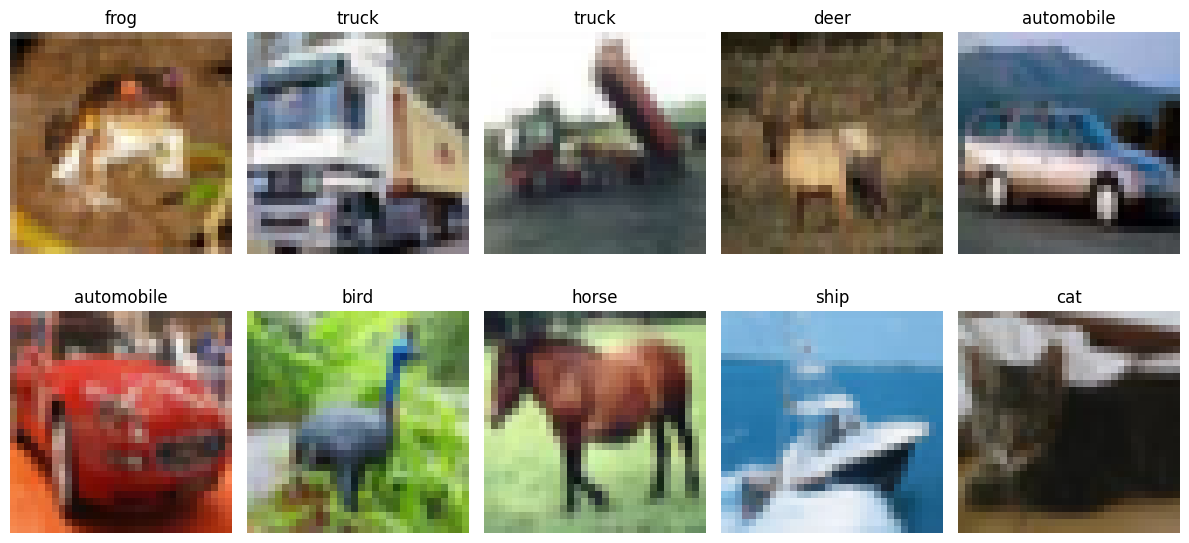

In [ ]:

class_names = [
    "airplane",
    "automobile",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck"
]

print("Number of classes:", len(class_names))

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i])
    plt.title(class_names[y_train[i][0]])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import tensorflow as tf
from tensorflow.keras.applications import VGG16

# Normalize data before using it
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

# Load pretrained VGG16 without the original classifier
base_model = VGG16(
    weights='imagenet',
    include_top=False,
    input_shape=(32, 32, 3)
)

# Freeze convolutional base
base_model.trainable = False

# Build transfer learning model
model = tf.keras.Sequential([
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

# Display model
model.summary()

Model: "sequential_21"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 1, 1, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_20     │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_43 (Dense)                │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_44 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,781,642 (56.39 MB)

 Trainable params: 66,954 (261.54 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [ ]:
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.optimizers import Adam

# Convert labels to one-hot encoding
y_train_cat = to_categorical(y_train, 10)
y_test_cat = to_categorical(y_test, 10)

# Compile model
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Train model
history = model.fit(
    x_train,
    y_train_cat,
    epochs=20,
    batch_size=32,
    validation_split=0.2
)

Epoch 1/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 19s 13ms/step - accuracy: 0.5110 - loss: 1.4002 - val_accuracy: 0.5622 - val_loss: 1.2636
Epoch 2/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 15s 10ms/step - accuracy: 0.5787 - loss: 1.2063 - val_accuracy: 0.5783 - val_loss: 1.2082
Epoch 3/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 16s 13ms/step - accuracy: 0.6008 - loss: 1.1483 - val_accuracy: 0.5886 - val_loss: 1.1789
Epoch 4/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 17s 10ms/step - accuracy: 0.6154 - loss: 1.1074 - val_accuracy: 0.5948 - val_loss: 1.1592
Epoch 5/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 13s 10ms/step - accuracy: 0.6242 - loss: 1.0766 - val_accuracy: 0.5970 - val_loss: 1.1628
Epoch 6/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 12s 10ms/step - accuracy: 0.6321 - loss: 1.0464 - val_accuracy: 0.5948 - val_loss: 1.1590
Epoch 7/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 12s 10ms/step - accuracy: 0.6427 - loss: 1.0187 - val_accuracy: 0.6042 - val_loss: 1.1489
Epoch 8/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 15s 12ms/step - accuracy: 0.6513 -

In [ ]:
test_loss, test_accuracy = model.evaluate(
    x_test,
    y_test_cat,
    verbose=0
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

Test Loss: 1.2380038499832153
Test Accuracy: 0.5996999740600586


In [ ]:
import numpy as np
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix

# Actual labels
y_true = y_test.flatten().astype(int)

# Predictions from the normal/base model
base_output = model.predict(x_test)
base_pred = np.argmax(base_output, axis=1)

# Store classification metrics
base_accuracy = accuracy_score(y_true, base_pred)

base_precision = precision_score(
    y_true, base_pred, average='weighted'
)

base_recall = recall_score(
    y_true, base_pred, average='weighted'
)

base_f1 = f1_score(
    y_true, base_pred, average='weighted'
)

# Store confusion matrix
base_cm = confusion_matrix(y_true, base_pred)

# Store classification report
base_report = classification_report(
    y_true,
    base_pred,
    target_names=[
        'airplane', 'automobile', 'bird', 'cat', 'deer',
        'dog', 'frog', 'horse', 'ship', 'truck'
    ]
)

print("BASE MODEL RESULTS")
print("Accuracy :", base_accuracy)
print("Precision:", base_precision)
print("Recall   :", base_recall)
print("F1-Score :", base_f1)

print("\nClassification Report:")
print(base_report)

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step
BASE MODEL RESULTS
Accuracy : 0.5997
Precision: 0.6010644491625214
Recall   : 0.5997
F1-Score : 0.5923914014273484

Classification Report:
              precision    recall  f1-score   support

    airplane       0.64      0.73      0.68      1000
  automobile       0.65      0.71      0.68      1000
        bird       0.61      0.43      0.50      1000
         cat       0.50      0.31      0.38      1000
        deer       0.59      0.51      0.55      1000
         dog       0.53      0.54      0.53      1000
        frog       0.54      0.75      0.63      1000
       horse       0.71      0.58      0.64      1000
        ship       0.71      0.72      0.71      1000
       truck       0.54      0.72      0.61      1000

    accuracy                           0.60     10000
   macro avg       0.60      0.60      0.59     10000
weighted avg       0.60      0.60      0.59     10000



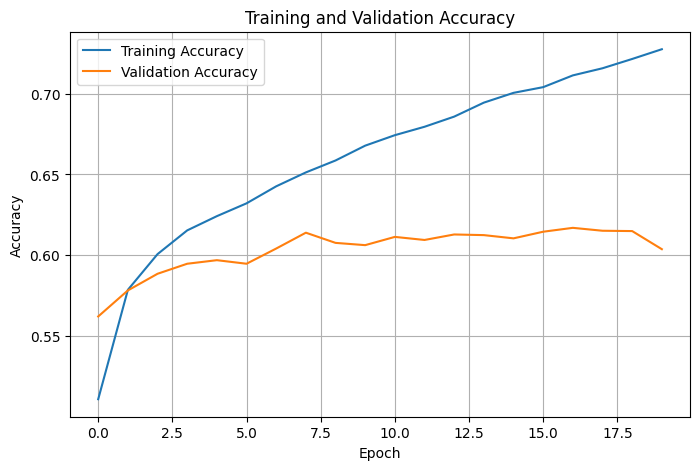

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend()
plt.grid()
plt.show()

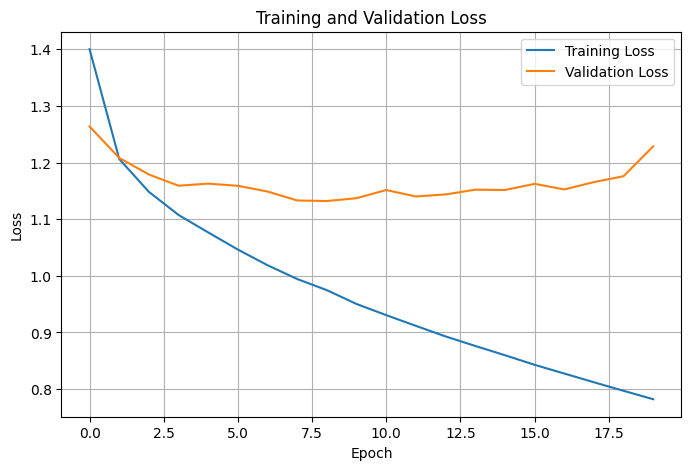

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.grid()
plt.show()

In [ ]:
# Keep all VGG16 layers frozen
base_model.trainable = False

# Unfreeze the last convolution block (Block 5)
for layer in base_model.layers:
    if layer.name.startswith('block5'):
        layer.trainable = True

# Check trainable layers
for layer in base_model.layers:
    if layer.trainable:
        print(layer.name)

block5_conv1
block5_conv2
block5_conv3
block5_pool


In [ ]:
from tensorflow.keras.optimizers import Adam

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)
fine_tune_history = model.fit(
    x_train,
    y_train_cat,
    epochs=10,
    batch_size=32,
    validation_split=0.2
)


Epoch 1/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 20s 14ms/step - accuracy: 0.6044 - loss: 1.1374 - val_accuracy: 0.6877 - val_loss: 0.8974
Epoch 2/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 18s 14ms/step - accuracy: 0.7104 - loss: 0.8436 - val_accuracy: 0.6939 - val_loss: 0.8841
Epoch 3/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 20s 14ms/step - accuracy: 0.7484 - loss: 0.7349 - val_accuracy: 0.7105 - val_loss: 0.8519
Epoch 4/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 16s 13ms/step - accuracy: 0.7742 - loss: 0.6575 - val_accuracy: 0.7320 - val_loss: 0.7943
Epoch 5/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 16s 13ms/step - accuracy: 0.7958 - loss: 0.5943 - val_accuracy: 0.7331 - val_loss: 0.8048
Epoch 6/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 16s 13ms/step - accuracy: 0.8161 - loss: 0.5336 - val_accuracy: 0.7356 - val_loss: 0.8195
Epoch 7/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 19s 15ms/step - accuracy: 0.8317 - loss: 0.4794 - val_accuracy: 0.7309 - val_loss: 0.8792
Epoch 8/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 17s 13ms/step - accuracy: 0.8495 -

In [ ]:
fine_loss, fine_accuracy = model.evaluate(
    x_test,
    y_test_cat,
    verbose=0
)

print("Accuracy before fine tuning:", test_accuracy)
print("Accuracy after fine tuning :", fine_accuracy)

Accuracy before fine tuning: 0.5990999937057495
Accuracy after fine tuning : 0.7311000227928162


In [ ]:
import numpy as np
from sklearn.metrics import accuracy_score, precision_score
from sklearn.metrics import recall_score, f1_score, confusion_matrix
from sklearn.metrics import classification_report

# Actual labels
y_true_fine = y_test.flatten().astype(int)

# Fine-tuned model predictions
fine_output = model.predict(x_test)
fine_pred = np.argmax(fine_output, axis=1)

# Fine-tuned metrics
fine_accuracy = accuracy_score(y_true_fine, fine_pred)

fine_precision = precision_score(
    y_true_fine,
    fine_pred,
    average='weighted'
)

fine_recall = recall_score(
    y_true_fine,
    fine_pred,
    average='weighted'
)

fine_f1 = f1_score(
    y_true_fine,
    fine_pred,
    average='weighted'
)

# Confusion matrix
fine_cm = confusion_matrix(
    y_true_fine,
    fine_pred
)

# Classification report
fine_report = classification_report(
    y_true_fine,
    fine_pred,
    target_names=[
        'airplane', 'automobile', 'bird', 'cat', 'deer',
        'dog', 'frog', 'horse', 'ship', 'truck'
    ]
)

print("FINE-TUNED MODEL")
print("Accuracy :", fine_accuracy)
print("Precision:", fine_precision)
print("Recall   :", fine_recall)
print("F1-Score :", fine_f1)

print("\nClassification Report:")
print(fine_report)

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step
FINE-TUNED MODEL
Accuracy : 0.7311
Precision: 0.7311263985702686
Recall   : 0.7311
F1-Score : 0.729431976785905

Classification Report:
              precision    recall  f1-score   support

    airplane       0.76      0.81      0.79      1000
  automobile       0.80      0.85      0.83      1000
        bird       0.66      0.67      0.67      1000
         cat       0.55      0.54      0.54      1000
        deer       0.77      0.59      0.67      1000
         dog       0.62      0.62      0.62      1000
        frog       0.73      0.79      0.76      1000
       horse       0.75      0.81      0.78      1000
        ship       0.85      0.86      0.85      1000
       truck       0.81      0.77      0.79      1000

    accuracy                           0.73     10000
   macro avg       0.73      0.73      0.73     10000
weighted avg       0.73      0.73      0.73     10000



In [ ]:
import pandas as pd

comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score"
    ],
    "Base VGG16": [
        base_accuracy,
        base_precision,
        base_recall,
        base_f1
    ],
    "Fine-Tuned VGG16": [
        fine_accuracy,
        fine_precision,
        fine_recall,
        fine_f1
    ]
})

print(comparison.to_string(index=False))

   Metric  Base VGG16  Fine-Tuned VGG16
 Accuracy    0.599100          0.731100
Precision    0.603113          0.731126
   Recall    0.599100          0.731100
 F1-Score    0.597479          0.729432


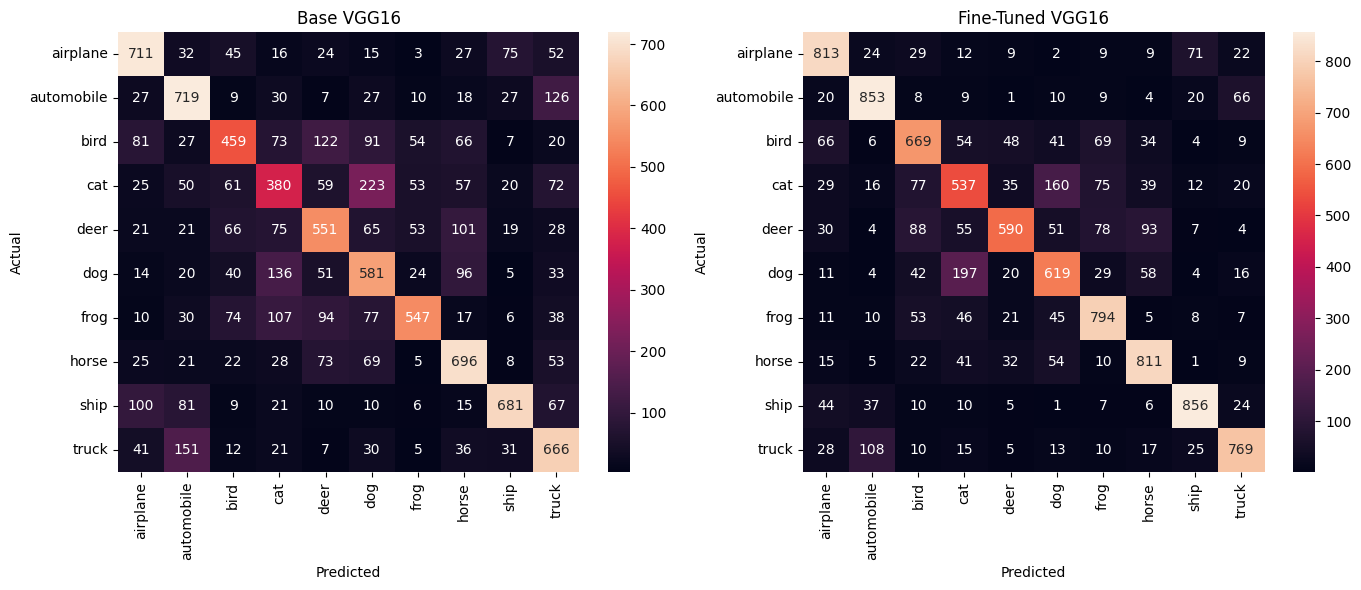

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

class_names = [
    'airplane', 'automobile', 'bird', 'cat', 'deer',
    'dog', 'frog', 'horse', 'ship', 'truck'
]

plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
sns.heatmap(
    base_cm,
    annot=True,
    fmt='d',
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("Base VGG16")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.subplot(1, 2, 2)
sns.heatmap(
    fine_cm,
    annot=True,
    fmt='d',
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("Fine-Tuned VGG16")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()

In [ ]:
import tensorflow as tf

# ---------- Batch Size Study ----------

batch_sizes = [32, 64]
results_batch = {}

for batch in batch_sizes:

    print("\nBatch Size:", batch)

    base = tf.keras.applications.VGG16(
        weights='imagenet',
        include_top=False,
        input_shape=(32, 32, 3)
    )
    base.trainable = False

    batch_model = tf.keras.Sequential([
        base,
        tf.keras.layers.GlobalAveragePooling2D(),
        tf.keras.layers.Dense(128, activation='relu'),
        tf.keras.layers.Dense(10, activation='softmax')
    ])

    batch_model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    history = batch_model.fit(
        x_train,
        y_train_cat,
        epochs=5,
        batch_size=batch,
        validation_split=0.2,
        verbose=1
    )

    _, test_acc = batch_model.evaluate(
        x_test,
        y_test_cat,
        verbose=0
    )

    results_batch[batch] = test_acc

# ---------- Comparison ----------

print("\nBatch Size Comparison")

for batch, acc in results_batch.items():
    print(f"Batch Size = {batch}: Test Accuracy = {acc:.4f}")


Batch Size: 32
Epoch 1/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 18s 12ms/step - accuracy: 0.5135 - loss: 1.3967 - val_accuracy: 0.5554 - val_loss: 1.2731
Epoch 2/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 13s 10ms/step - accuracy: 0.5775 - loss: 1.2059 - val_accuracy: 0.5820 - val_loss: 1.1963
Epoch 3/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 13s 10ms/step - accuracy: 0.5993 - loss: 1.1483 - val_accuracy: 0.5827 - val_loss: 1.1931
Epoch 4/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 13s 10ms/step - accuracy: 0.6125 - loss: 1.1097 - val_accuracy: 0.5991 - val_loss: 1.1718
Epoch 5/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 13s 10ms/step - accuracy: 0.6237 - loss: 1.0769 - val_accuracy: 0.5964 - val_loss: 1.1570

Batch Size: 64
Epoch 1/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 16s 19ms/step - accuracy: 0.5032 - loss: 1.4408 - val_accuracy: 0.5542 - val_loss: 1.2780
Epoch 2/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.5715 - loss: 1.2283 - val_accuracy: 0.5792 - val_loss: 1.2125
Epoch 3/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 11s 17ms/step - 

In [ ]:
import tensorflow as tf

# ---------- Optimizer Study ----------

optimizers = {
    "Adam": tf.keras.optimizers.Adam(learning_rate=0.001),
    "SGD": tf.keras.optimizers.SGD(learning_rate=0.001)
}

results_optimizer = {}

for name, optimizer in optimizers.items():

    print("\nOptimizer:", name)

    base = tf.keras.applications.VGG16(
        weights='imagenet',
        include_top=False,
        input_shape=(32, 32, 3)
    )
    base.trainable = False

    optimizer_model = tf.keras.Sequential([
        base,
        tf.keras.layers.GlobalAveragePooling2D(),
        tf.keras.layers.Dense(128, activation='relu'),
        tf.keras.layers.Dense(10, activation='softmax')
    ])

    optimizer_model.compile(
        optimizer=optimizer,
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    history = optimizer_model.fit(
        x_train,
        y_train_cat,
        epochs=5,
        batch_size=32,
        validation_split=0.2,
        verbose=1
    )

    _, test_acc = optimizer_model.evaluate(
        x_test,
        y_test_cat,
        verbose=0
    )

    results_optimizer[name] = test_acc

# ---------- Comparison ----------

print("\nOptimizer Comparison")

for name, acc in results_optimizer.items():
    print(f"{name}: Test Accuracy = {acc:.4f}")


Optimizer: Adam
Epoch 1/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 19s 12ms/step - accuracy: 0.5128 - loss: 1.4014 - val_accuracy: 0.5657 - val_loss: 1.2537
Epoch 2/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 13s 10ms/step - accuracy: 0.5794 - loss: 1.2104 - val_accuracy: 0.5830 - val_loss: 1.2047
Epoch 3/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 13s 10ms/step - accuracy: 0.5981 - loss: 1.1497 - val_accuracy: 0.5840 - val_loss: 1.1897
Epoch 4/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 13s 10ms/step - accuracy: 0.6096 - loss: 1.1113 - val_accuracy: 0.5940 - val_loss: 1.1681
Epoch 5/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 12s 10ms/step - accuracy: 0.6229 - loss: 1.0766 - val_accuracy: 0.6030 - val_loss: 1.1485

Optimizer: SGD
Epoch 1/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 16s 11ms/step - accuracy: 0.2136 - loss: 2.1947 - val_accuracy: 0.2860 - val_loss: 2.0796
Epoch 2/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 13s 10ms/step - accuracy: 0.3284 - loss: 2.0008 - val_accuracy: 0.3542 - val_loss: 1.9229
Epoch 3/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 21s 10ms/

In [ ]:
import tensorflow as tf

# ---------- Dense Units Study ----------

dense_units = [128, 256]
results_dense = {}

for units in dense_units:

    print("\nDense Units:", units)

    base = tf.keras.applications.VGG16(
        weights='imagenet',
        include_top=False,
        input_shape=(32, 32, 3)
    )
    base.trainable = False

    dense_model = tf.keras.Sequential([
        base,
        tf.keras.layers.GlobalAveragePooling2D(),
        tf.keras.layers.Dense(units, activation='relu'),
        tf.keras.layers.Dense(10, activation='softmax')
    ])

    dense_model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    history = dense_model.fit(
        x_train,
        y_train_cat,
        epochs=5,
        batch_size=32,
        validation_split=0.2,
        verbose=1
    )

    _, test_acc = dense_model.evaluate(
        x_test,
        y_test_cat,
        verbose=0
    )

    results_dense[units] = test_acc

# ---------- Comparison ----------

print("\nDense Units Comparison")

for units, acc in results_dense.items():
    print(f"Dense Units = {units}: Test Accuracy = {acc:.4f}")


Dense Units: 128
Epoch 1/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 18s 12ms/step - accuracy: 0.5116 - loss: 1.4043 - val_accuracy: 0.5545 - val_loss: 1.2654
Epoch 2/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 12s 10ms/step - accuracy: 0.5792 - loss: 1.2097 - val_accuracy: 0.5879 - val_loss: 1.1898
Epoch 3/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 13s 10ms/step - accuracy: 0.5971 - loss: 1.1521 - val_accuracy: 0.5931 - val_loss: 1.1753
Epoch 4/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 14s 11ms/step - accuracy: 0.6136 - loss: 1.1090 - val_accuracy: 0.5958 - val_loss: 1.1610
Epoch 5/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 13s 10ms/step - accuracy: 0.6220 - loss: 1.0777 - val_accuracy: 0.5978 - val_loss: 1.1506

Dense Units: 256
Epoch 1/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 18s 12ms/step - accuracy: 0.5202 - loss: 1.3667 - val_accuracy: 0.5593 - val_loss: 1.2444
Epoch 2/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 13s 10ms/step - accuracy: 0.5846 - loss: 1.1823 - val_accuracy: 0.5893 - val_loss: 1.1681
Epoch 3/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 13s 10

In [ ]:
import tensorflow as tf

# ---------- Epoch Study ----------

epochs_list = [10, 20]
results_epochs = {}

for epochs in epochs_list:

    print("\nEpochs:", epochs)

    base = tf.keras.applications.VGG16(
        weights='imagenet',
        include_top=False,
        input_shape=(32, 32, 3)
    )
    base.trainable = False

    epoch_model = tf.keras.Sequential([
        base,
        tf.keras.layers.GlobalAveragePooling2D(),
        tf.keras.layers.Dense(128, activation='relu'),
        tf.keras.layers.Dense(10, activation='softmax')
    ])

    epoch_model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    history = epoch_model.fit(
        x_train,
        y_train_cat,
        epochs=epochs,
        batch_size=32,
        validation_split=0.2,
        verbose=1
    )

    _, test_acc = epoch_model.evaluate(
        x_test,
        y_test_cat,
        verbose=0
    )

    results_epochs[epochs] = test_acc

# ---------- Comparison ----------

print("\nEpoch Comparison")

for epochs, acc in results_epochs.items():
    print(f"Epochs = {epochs}: Test Accuracy = {acc:.4f}")


Epochs: 10
Epoch 1/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 18s 12ms/step - accuracy: 0.5124 - loss: 1.4030 - val_accuracy: 0.5558 - val_loss: 1.2719
Epoch 2/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 13s 10ms/step - accuracy: 0.5791 - loss: 1.2073 - val_accuracy: 0.5849 - val_loss: 1.1857
Epoch 3/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 13s 10ms/step - accuracy: 0.5985 - loss: 1.1462 - val_accuracy: 0.5912 - val_loss: 1.1736
Epoch 4/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 13s 10ms/step - accuracy: 0.6132 - loss: 1.1074 - val_accuracy: 0.5995 - val_loss: 1.1509
Epoch 5/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 13s 10ms/step - accuracy: 0.6246 - loss: 1.0714 - val_accuracy: 0.5979 - val_loss: 1.1503
Epoch 6/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 13s 10ms/step - accuracy: 0.6353 - loss: 1.0429 - val_accuracy: 0.6043 - val_loss: 1.1447
Epoch 7/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 13s 10ms/step - accuracy: 0.6433 - loss: 1.0145 - val_accuracy: 0.6095 - val_loss: 1.1379
Epoch 8/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 13s 10ms/step - accura

In [ ]:
import tensorflow as tf

# ---------- Learning Rate Study ----------

learning_rates = [0.001, 0.0001]
results_lr = {}

for lr in learning_rates:

    print("\nLearning Rate:", lr)

    base = tf.keras.applications.VGG16(
        weights='imagenet',
        include_top=False,
        input_shape=(32, 32, 3)
    )
    base.trainable = False

    lr_model = tf.keras.Sequential([
        base,
        tf.keras.layers.GlobalAveragePooling2D(),
        tf.keras.layers.Dense(128, activation='relu'),
        tf.keras.layers.Dense(10, activation='softmax')
    ])

    lr_model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    history = lr_model.fit(
        x_train,
        y_train_cat,
        epochs=5,
        batch_size=32,
        validation_split=0.2,
        verbose=1
    )

    _, test_acc = lr_model.evaluate(
        x_test,
        y_test_cat,
        verbose=0
    )

    results_lr[lr] = test_acc

# ---------- Comparison ----------

print("\nLearning Rate Comparison")

for lr, acc in results_lr.items():
    print(f"Learning Rate = {lr}: Test Accuracy = {acc:.4f}")


Learning Rate: 0.001
Epoch 1/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 17s 12ms/step - accuracy: 0.5108 - loss: 1.4019 - val_accuracy: 0.5635 - val_loss: 1.2505
Epoch 2/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 13s 10ms/step - accuracy: 0.5774 - loss: 1.2074 - val_accuracy: 0.5720 - val_loss: 1.2252
Epoch 3/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 13s 10ms/step - accuracy: 0.5974 - loss: 1.1474 - val_accuracy: 0.5846 - val_loss: 1.2047
Epoch 4/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 13s 10ms/step - accuracy: 0.6112 - loss: 1.1092 - val_accuracy: 0.5925 - val_loss: 1.1671
Epoch 5/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 13s 10ms/step - accuracy: 0.6258 - loss: 1.0718 - val_accuracy: 0.6060 - val_loss: 1.1404

Learning Rate: 0.0001
Epoch 1/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 17s 12ms/step - accuracy: 0.3913 - loss: 1.8028 - val_accuracy: 0.4850 - val_loss: 1.5311
Epoch 2/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 13s 10ms/step - accuracy: 0.5111 - loss: 1.4455 - val_accuracy: 0.5187 - val_loss: 1.3926
Epoch 3/5
1250/1250 ━━━━━━━━━━━━━━━━━━

In [ ]:
import tensorflow as tf

# ---------- ResNet50 for CIFAR-10 ----------

resnet_model = tf.keras.Sequential([
    tf.keras.applications.ResNet50(
        weights=None,
        include_top=False,
        input_shape=(32, 32, 3),
        pooling='avg'
    ),

    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(10, activation='softmax')
])

resnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

resnet_history = resnet_model.fit(
    x_train,
    y_train_cat,
    epochs=10,
    batch_size=32,
    validation_split=0.2
)

resnet_loss, resnet_accuracy = resnet_model.evaluate(
    x_test,
    y_test_cat,
    verbose=1
)

print("ResNet50 Test Accuracy:", resnet_accuracy)
print("ResNet50 Parameters:", resnet_model.count_params())

Epoch 1/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 101s 38ms/step - accuracy: 0.2328 - loss: 1.9942 - val_accuracy: 0.2045 - val_loss: 2.5548
Epoch 2/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 42s 34ms/step - accuracy: 0.3173 - loss: 1.7943 - val_accuracy: 0.1164 - val_loss: 3.2847
Epoch 3/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 40s 32ms/step - accuracy: 0.3106 - loss: 1.8303 - val_accuracy: 0.3487 - val_loss: 1.7627
Epoch 4/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 39s 31ms/step - accuracy: 0.3488 - loss: 1.7485 - val_accuracy: 0.2507 - val_loss: 2.0631
Epoch 5/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 39s 31ms/step - accuracy: 0.3869 - loss: 1.6753 - val_accuracy: 0.3094 - val_loss: 2.1274
Epoch 6/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 40s 32ms/step - accuracy: 0.3941 - loss: 1.6476 - val_accuracy: 0.4334 - val_loss: 1.5900
Epoch 7/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 39s 31ms/step - accuracy: 0.4435 - loss: 1.5390 - val_accuracy: 0.4370 - val_loss: 1.5683
Epoch 8/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 40s 32ms/step - accuracy: 0.4506 

In [ ]:
import tensorflow as tf

# ---------- LeNet-5 ----------

lenet_model = tf.keras.Sequential([
    tf.keras.layers.Conv2D(6, (5, 5), activation='relu',
                           input_shape=(32, 32, 3)),
    tf.keras.layers.AveragePooling2D((2, 2)),

    tf.keras.layers.Conv2D(16, (5, 5), activation='relu'),
    tf.keras.layers.AveragePooling2D((2, 2)),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(120, activation='relu'),
    tf.keras.layers.Dense(84, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

lenet_model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

lenet_history = lenet_model.fit(
    x_train,
    y_train_cat,
    epochs=10,
    batch_size=32,
    validation_split=0.2
)

_, lenet_accuracy = lenet_model.evaluate(
    x_test,
    y_test_cat,
    verbose=0
)

print("LeNet-5 Test Accuracy:", lenet_accuracy)
print("LeNet-5 Parameters:", lenet_model.count_params())

Epoch 1/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.3760 - loss: 1.7123 - val_accuracy: 0.4405 - val_loss: 1.5701
Epoch 2/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.4814 - loss: 1.4396 - val_accuracy: 0.4979 - val_loss: 1.4070
Epoch 3/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.5190 - loss: 1.3339 - val_accuracy: 0.5329 - val_loss: 1.3155
Epoch 4/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.5507 - loss: 1.2568 - val_accuracy: 0.5493 - val_loss: 1.2754
Epoch 5/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.5704 - loss: 1.2043 - val_accuracy: 0.5478 - val_loss: 1.2793
Epoch 6/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.5863 - loss: 1.1529 - val_accuracy: 0.5669 - val_loss: 1.2189
Epoch 7/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.6042 - loss: 1.1092 - val_accuracy: 0.5633 - val_loss: 1.2367
Epoch 8/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.6206 - loss: 1.0686 - 

In [ ]:
import tensorflow as tf

# ---------- CIFAR-10 AlexNet ----------

alexnet_model = tf.keras.Sequential([
    # Block 1
    tf.keras.layers.Conv2D(
        64, (3, 3),
        activation='relu',
        padding='same',
        input_shape=(32, 32, 3)
    ),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Block 2
    tf.keras.layers.Conv2D(
        128, (3, 3),
        activation='relu',
        padding='same'
    ),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Block 3
    tf.keras.layers.Conv2D(
        256, (3, 3),
        activation='relu',
        padding='same'
    ),
    tf.keras.layers.Conv2D(
        256, (3, 3),
        activation='relu',
        padding='same'
    ),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Classifier
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(256, activation='relu'),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(10, activation='softmax')
])

alexnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

alexnet_history = alexnet_model.fit(
    x_train,
    y_train_cat,
    epochs=10,
    batch_size=32,
    validation_split=0.2
)

alexnet_loss, alexnet_accuracy = alexnet_model.evaluate(
    x_test,
    y_test_cat,
    verbose=1
)

print("AlexNet Test Accuracy:", alexnet_accuracy)
print("AlexNet Parameters:", alexnet_model.count_params())

Epoch 1/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 16s 9ms/step - accuracy: 0.3836 - loss: 1.6555 - val_accuracy: 0.5409 - val_loss: 1.2545
Epoch 2/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 10s 8ms/step - accuracy: 0.5667 - loss: 1.2103 - val_accuracy: 0.6289 - val_loss: 1.0572
Epoch 3/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 11s 9ms/step - accuracy: 0.6504 - loss: 1.0001 - val_accuracy: 0.6714 - val_loss: 0.9364
Epoch 4/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 9s 7ms/step - accuracy: 0.6996 - loss: 0.8568 - val_accuracy: 0.7050 - val_loss: 0.8592
Epoch 5/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 10s 8ms/step - accuracy: 0.7373 - loss: 0.7532 - val_accuracy: 0.7293 - val_loss: 0.7876
Epoch 6/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 10s 8ms/step - accuracy: 0.7698 - loss: 0.6611 - val_accuracy: 0.7367 - val_loss: 0.7888
Epoch 7/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 9s 8ms/step - accuracy: 0.7944 - loss: 0.5880 - val_accuracy: 0.7486 - val_loss: 0.7742
Epoch 8/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 10s 8ms/step - accuracy: 0.8167 - loss: 0.5

In [ ]:
print("\nArchitecture Comparison")

print("LeNet-5  | Parameters:", lenet_model.count_params(),
      "| Accuracy:", lenet_accuracy)

print("AlexNet  | Parameters:", alexnet_model.count_params(),
      "| Accuracy:", alexnet_accuracy)

print("ResNet50 | Parameters:", resnet_model.count_params(),
      "| Accuracy:", resnet_accuracy)


Architecture Comparison
LeNet-5  | Parameters: 62006 | Accuracy: 0.5785999894142151
AlexNet  | Parameters: 2012298 | Accuracy: 0.7408999800682068
ResNet50 | Parameters: 23851274 | Accuracy: 0.4666000008583069
